# LAB 08 — Pretrained Transformers và BERT fine-tuning

Notebook thực nghiệm mục **12–22**. Chạy theo thứ tự; câu hỏi được ghi ngay sau mỗi experiment để trả lời **sau khi có kết quả**. Không có kết quả giả lập. Giữ `pretrained_classification.py` cùng thư mục notebook. Các kết quả validation dùng để so sánh; test chỉ dùng đánh giá cuối và phân tích lỗi.

## 0. Chuẩn bị
Trên Colab chọn GPU, đặt `aclImdb_v1.tar.gz` ở `/content/` và tải `pretrained_classification.py` lên thư mục làm việc. Cần Internet để tải model/tokenizer Hugging Face. Chế độ `quick` chỉ để kiểm tra pipeline, không dùng số liệu đó như kết quả đầy đủ. Domain B cần file CSV `text,label` riêng, nhãn 0=negative, 1=positive; không sử dụng văn bản IMDb trong domain B.

Cần thêm package `datasets` cho Amazon Polarity (`%pip install -q datasets`). T4 có thể thử batch 16; nếu hết VRAM giảm xuống 8 và chạy lại từ đầu để các thí nghiệm dùng cấu hình nhất quán.

In [ ]:
# Bỏ dấu # nếu môi trường chưa có các thư viện:
# %pip install -q torch transformers scikit-learn pandas numpy matplotlib psutil
from pathlib import Path
import gc, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from IPython.display import display
import pretrained_classification as pc

MODEL_NAME = 'bert-base-uncased'
PROFILE = 'quick'  # full hoặc quick
SEED = 42
BATCH_SIZE = 64
EPOCHS = 3
LR = 3e-5
BASE_LENGTH = 256
ARCHIVE = Path('/content/aclImdb_v1.tar.gz')
IMDB_ROOT = Path('/content/w4/aclImdb')
DOMAIN_B_CSV = Path('data/domain_b.csv')
OUT = Path('lab8_artifacts'); OUT.mkdir(exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
pc.seed_all(SEED)
print('Device:', DEVICE, '| profile:', PROFILE, '| model:', MODEL_NAME)
if PROFILE not in ['full', 'quick']: raise ValueError('PROFILE phải là full hoặc quick')
if DEVICE == 'cpu': print('Cảnh báo: full BERT có thể chạy rất lâu trên CPU.')

Device: cuda | profile: quick | model: bert-base-uncased


## 1. Dữ liệu và phân chia giống LAB 7
Gộp 4 thư mục IMDb train/test × neg/pos, tính MD5 từ văn bản làm sạch giống LAB 7, rồi chia theo **nhóm** bằng hai lần `train_test_split` với seed 42, tỷ lệ nhóm 70/15/15 và stratify theo nhãn. Vì nhóm có thể có nhiều review, tỷ lệ số dòng có thể lệch nhẹ. `source_id` phản ánh nguồn IMDb ban đầu, không phải split hiện tại. BERT nhận văn bản gốc; việc làm sạch chỉ phục vụ tạo nhóm.

In [ ]:
data = pc.load_imdb_like_lab7(ARCHIVE, IMDB_ROOT)
train_df, val_df, test_df = pc.split_like_lab7(data, SEED)
if PROFILE == 'quick':
    train_df = pc.subset(train_df, 8000, SEED)
    val_df = pc.subset(val_df, 1000, SEED)
    test_df = pc.subset(test_df, 1000, SEED)
manifest = pd.concat([df[['source_id','label','group']].assign(split=name) for name,df in
                      [('train',train_df),('validation',val_df),('test',test_df)]], ignore_index=True)
manifest.to_csv(OUT/'split_manifest.csv',index=False)
display(manifest.groupby(['split','label']).size().unstack(fill_value=0))
print('Tổng:', len(manifest), '| nhóm giữa các split không trùng.')
tokenizer = pc.load_tokenizer(MODEL_NAME)

label,0,1
split,,
test,500,500
train,4001,3999
validation,499,501


Tổng: 10000 | nhóm giữa các split không trùng.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


## 12. Core Implementation — Tokenization
Kiểm tra keys, token và padding bằng tokenizer của model. `input_ids` là ID của token, bao gồm token đặc biệt và padding. `attention_mask` thường bằng 1 tại vị trí token thật (kể cả token đặc biệt), bằng 0 tại padding. Có thể xuất hiện `token_type_ids` tùy tokenizer.

In [ ]:
sample = ['This movie was excellent.', 'I did not like it.']
tokens = tokenizer(sample, padding=True, truncation=True, max_length=BASE_LENGTH, return_tensors='pt')
print('tokens.keys():', tokens.keys())
for key, value in tokens.items(): print(key, value)
print('Tokens:', tokenizer.convert_ids_to_tokens(tokens['input_ids'][0]))

tokens.keys(): KeysView({'input_ids': tensor([[ 101, 2023, 3185, 2001, 6581, 1012,  102,    0],
        [ 101, 1045, 2106, 2025, 2066, 2009, 1012,  102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1, 1]])})
input_ids tensor([[ 101, 2023, 3185, 2001, 6581, 1012,  102,    0],
        [ 101, 1045, 2106, 2025, 2066, 2009, 1012,  102]])
token_type_ids tensor([[0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0]])
attention_mask tensor([[1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1, 1]])
Tokens: ['[CLS]', 'this', 'movie', 'was', 'excellent', '.', '[SEP]', '[PAD]']


## 13. Classification head
Pipeline: văn bản → tokenizer → input IDs + attention mask → BERT → contextual representations → vector `[CLS]` (vị trí 0) → dropout + linear → logits → softmax → nhãn. Linear head là **task-specific** và được khởi tạo mới để học hai nhãn. Cross entropy nhận logits thô; softmax chỉ dùng khi suy luận/đo confidence. Mã đầy đủ ở `CLSClassifier` trong `pretrained_classification.py`.

In [ ]:
demo_model = pc.CLSClassifier(MODEL_NAME, pretrained=True).to(DEVICE).eval()
with torch.no_grad():
    demo_logits = demo_model(**{k:v.to(DEVICE) for k,v in tokens.items()})
    demo_prob = demo_logits.softmax(dim=-1)
print('Logits:', demo_logits.cpu())
print('Softmax:', demo_prob.cpu())
print('Nhãn minh họa trước huấn luyện:', [pc.LABEL_NAMES[i] for i in demo_prob.argmax(-1).tolist()])
del demo_model; gc.collect()
if DEVICE == 'cuda': torch.cuda.empty_cache()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Logits: tensor([[-0.2293, -0.3060],
        [-0.2486, -0.2202]])
Softmax: tensor([[0.5192, 0.4808],
        [0.4929, 0.5071]])
Nhãn minh họa trước huấn luyện: ['negative', 'positive']


## Thiết lập thực nghiệm chung
Các model có cùng kiến trúc BERT, tokenizer, split, sequence length và số epoch trừ biến được nêu. Model scratch khởi tạo encoder ngẫu nhiên từ cấu hình BERT, vẫn dùng tokenizer pretrained; vì vậy thí nghiệm cô lập ảnh hưởng của **trọng số encoder pretrained**, không phải toàn bộ pipeline pretrained. Mỗi run khởi tạo lại seed, lưu checkpoint và history; chọn epoch theo validation loss. F1 là **macro F1**. Thời gian gồm train và validation theo epoch; không gồm tải model/tokenization. CPU RSS là đỉnh của toàn tiến trình, GPU là đỉnh allocated của PyTorch; chúng không đo cùng một đại lượng.

In [ ]:
def run_and_save(run_id, training, pretrained=True, frozen=False, length=BASE_LENGTH):
    print('\nRUN:', run_id)
    model, record, history = pc.train_run(training, val_df, tokenizer, model_name=MODEL_NAME,
        pretrained=pretrained, freeze=frozen, max_length=length, batch_size=BATCH_SIZE,
        epochs=EPOCHS, lr=LR, seed=SEED, device=DEVICE)
    record['run_id'] = run_id
    torch.save({'state_dict': {k:v.cpu() for k,v in model.state_dict().items()},
                'pretrained':pretrained, 'frozen':frozen, 'length':length}, OUT/f'{run_id}.pt')
    history.to_csv(OUT/f'{run_id}_history.csv',index=False)
    del model; gc.collect()
    if DEVICE == 'cuda': torch.cuda.empty_cache()
    return record

def restore(run_id):
    ck = torch.load(OUT/f'{run_id}.pt', map_location='cpu', weights_only=True)
    model = pc.CLSClassifier(MODEL_NAME, pretrained=False, freeze=ck['frozen'])
    model.load_state_dict(ck['state_dict']); return model.to(DEVICE), ck['length']

config = dict(model=MODEL_NAME, tokenizer=MODEL_NAME, dataset='IMDb aclImdb', split='group-aware 70/15/15 LAB7',
              split_seed=SEED, profile=PROFILE, n_train=len(train_df),n_validation=len(val_df),n_test=len(test_df),
              batch_size=BATCH_SIZE, epochs=EPOCHS,learning_rate=LR, max_length=BASE_LENGTH, device=DEVICE,
              torch=torch.__version__,python=platform.python_version())
(OUT/'run_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')

394

## 14. Experiment 1 — Pretrained vs From Scratch
**Thực nghiệm:** Cùng kiến trúc, dữ liệu và cấu hình; so sánh encoder khởi tạo ngẫu nhiên với encoder pretrained. Tất cả tham số đều được huấn luyện. Lưu ý số epoch/LR chung có thể chưa tối ưu như nhau cho hai chế độ.

In [ ]:
records = {}
records['scratch'] = run_and_save('scratch',train_df,pretrained=False)
records['finetuned'] = run_and_save('finetuned',train_df,pretrained=True)
exp1 = pd.DataFrame([records['scratch'],records['finetuned']])
exp1.to_csv(OUT/'exp1_pretrained_vs_scratch.csv',index=False)
display(exp1[['run_id','accuracy','f1_macro','training_time_s','parameters_total','parameters_trainable']])


RUN: scratch
epoch 1: train_loss=0.7676, val_loss=0.7180, val_f1=0.3338
epoch 2: train_loss=0.7101, val_loss=0.7005, val_f1=0.3329
epoch 3: train_loss=0.7051, val_loss=0.6923, val_f1=0.3923

RUN: finetuned


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1: train_loss=0.3187, val_loss=0.2421, val_f1=0.9067
epoch 2: train_loss=0.1665, val_loss=0.2344, val_f1=0.9160
epoch 3: train_loss=0.0673, val_loss=0.3058, val_f1=0.9180


,run_id,accuracy,f1_macro,training_time_s,parameters_total,parameters_trainable
0,scratch,0.522,0.392287,441.922895,109483778,109483778
1,finetuned,0.916,0.915997,444.115516,109483778,109483778


### Trả lời — Experiment 1: Pretrained vs From Scratch

1. **Representation:** Pretrained BERT đã học biểu diễn ngôn ngữ từ dữ liệu lớn, còn scratch khởi tạo ngẫu nhiên và chỉ học từ tập IMDb của bài. Accuracy validation tương ứng **91,6%** và **52,2%**; đây là bằng chứng gián tiếp về hiệu quả biểu diễn, không phải phép đo trực tiếp embedding.
2. **Training data:** Pretrained tận dụng dữ liệu ít hiệu quả hơn: chỉ **800 mẫu** đã đạt **88,8%** accuracy; scratch dùng **8.000 mẫu** chỉ đạt **52,2%**. Chưa chạy scratch ở các mức dữ liệu để định lượng chính xác nhu cầu dữ liệu của hai model.
3. **Chi phí:** Cùng ~**109,5 triệu** tham số trainable, thời gian scratch **441,9 s**, fine-tuning **444,1 s**, gần tương đương trong thí nghiệm này. **Không tính** chi phí pretraining BERT ban đầu; chỉ đo huấn luyện/validation downstream.
4. **So với prediction:** **Phù hợp** dự đoán pretrained tốt hơn scratch (Accuracy **91,6% > 52,2%**; Macro F1 **91,60% > 39,23%**). Kết luận chỉ áp dụng cho cấu hình **quick, 8.000 mẫu, 3 epochs** này.

## 15. Experiment 2 — Feature Extraction vs Fine-Tuning
**Thực nghiệm:** Frozen encoder và chỉ train head so với full fine-tuning. Dùng lại run fine-tuning từ Experiment 1 vì cấu hình hoàn toàn giống.

In [7]:
records['frozen'] = run_and_save('frozen',train_df,pretrained=True,frozen=True)
exp2=pd.DataFrame([records['frozen'],records['finetuned']])
exp2.to_csv(OUT/'exp2_frozen_vs_finetuned.csv',index=False)
display(exp2[['run_id','frozen','accuracy','f1_macro','training_time_s','parameters_trainable']])


RUN: frozen


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1: train_loss=0.6805, val_loss=0.6645, val_f1=0.6506
epoch 2: train_loss=0.6543, val_loss=0.6395, val_f1=0.7124
epoch 3: train_loss=0.6322, val_loss=0.6172, val_f1=0.7376


,run_id,frozen,accuracy,f1_macro,training_time_s,parameters_trainable
0,frozen,True,0.738,0.737621,177.085604,1538
1,finetuned,False,0.916,0.915997,444.115516,109483778


### Trả lời — Experiment 2: Frozen vs Fine-Tuning

1. **Vì sao frozen vẫn phân loại được?** Encoder pretrained tạo đặc trưng ngôn ngữ; classification head học ánh xạ những đặc trưng đó sang nhãn. Frozen đạt **73,8%** accuracy dù chỉ cập nhật **1.538** tham số.
2. **Vì sao fine-tuning tốt hơn?** Cho phép cập nhật encoder theo tác vụ IMDb, đạt **91,6%** accuracy và **91,60%** Macro F1, so với frozen **73,8%** và **73,76%**; đổi lại thời gian tăng từ **177,1 s** lên **444,1 s**.

## 16. Experiment 3 — Amount of Training Data
**Thực nghiệm:** Các tập 10%, 25%, 50%, 100% lồng nhau, lấy có phân tầng từ train; validation/test giữ cố định. Tất cả đều fine-tune từ cùng checkpoint pretrained. Đường cong này mô tả hiệu năng theo lượng dữ liệu; riêng đường cong này **không đủ** để so sánh trực tiếp hiệu quả dữ liệu với scratch.


RUN: data_10


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1: train_loss=0.6223, val_loss=0.4483, val_f1=0.7893
epoch 2: train_loss=0.3203, val_loss=0.2805, val_f1=0.8880
epoch 3: train_loss=0.1780, val_loss=0.4183, val_f1=0.8381

RUN: data_25


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1: train_loss=0.4711, val_loss=0.2857, val_f1=0.8869
epoch 2: train_loss=0.2161, val_loss=0.2501, val_f1=0.9050
epoch 3: train_loss=0.0920, val_loss=0.3923, val_f1=0.8637

RUN: data_50


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1: train_loss=0.3652, val_loss=0.2543, val_f1=0.8998
epoch 2: train_loss=0.1621, val_loss=0.2599, val_f1=0.9100
epoch 3: train_loss=0.0719, val_loss=0.3080, val_f1=0.9110


,fraction,n_train,accuracy,f1_macro
0,0.10,800,0.888,0.887971
1,0.25,2000,0.905,0.904998
2,0.50,4000,0.900,0.899823
3,1.00,8000,0.916,0.915997


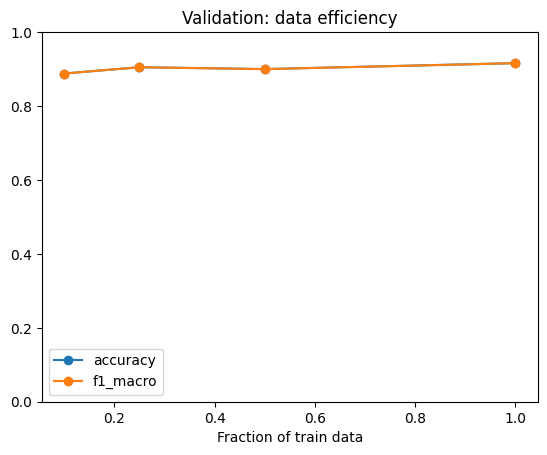

In [8]:
fractions=[.1,.25,.5,1.0]
subsets=pc.nested_subsets(train_df,fractions,SEED)
data_records=[]
for f in fractions:
    r=records['finetuned'].copy() if f==1.0 else run_and_save(f'data_{int(f*100)}',subsets[f])
    r['fraction']=f; data_records.append(r)
exp3=pd.DataFrame(data_records); exp3.to_csv(OUT/'exp3_data_amount.csv',index=False)
display(exp3[['fraction','n_train','accuracy','f1_macro']])
ax=exp3.plot(x='fraction',y=['accuracy','f1_macro'],marker='o',ylim=(0,1),title='Validation: data efficiency'); ax.set_xlabel('Fraction of train data'); plt.show()

### Trả lời — Experiment 3: Amount of Training Data

Pretraining **có dấu hiệu giúp** học hiệu quả với ít dữ liệu: **10% (800 mẫu) đạt 88,8%**, **25% đạt 90,5%**, **50% đạt 90,0%**, **100% đạt 91,6%** accuracy. Đường cong nhìn chung cải thiện nhưng **không tăng đơn điệu**. Chưa có đường cong scratch theo các mức dữ liệu, nên chưa thể khẳng định chính xác mức lợi thế dữ liệu so với scratch.

## 17. Experiment 4 — Maximum Sequence Length
**Thực nghiệm:** 64, 128, 256 token (tính cả special tokens); các yếu tố khác giữ nguyên. Run 128 được dùng lại.

In [9]:
length_records=[]
for length in [64,128,256]:
    r=records['finetuned'].copy() if length==BASE_LENGTH else run_and_save(f'length_{length}',train_df,length=length)
    length_records.append(r)
exp4=pd.DataFrame(length_records); exp4.to_csv(OUT/'exp4_sequence_length.csv',index=False)
display(exp4[['max_length','accuracy','f1_macro','training_time_s','cpu_peak_rss_mib','gpu_peak_allocated_mib']])


RUN: length_64


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1: train_loss=0.4608, val_loss=0.3854, val_f1=0.8148
epoch 2: train_loss=0.2900, val_loss=0.3899, val_f1=0.8298
epoch 3: train_loss=0.1459, val_loss=0.5651, val_f1=0.8054

RUN: length_128


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1: train_loss=0.3883, val_loss=0.2759, val_f1=0.8810
epoch 2: train_loss=0.2242, val_loss=0.2776, val_f1=0.8910
epoch 3: train_loss=0.1098, val_loss=0.3257, val_f1=0.8768


,max_length,accuracy,f1_macro,training_time_s,cpu_peak_rss_mib,gpu_peak_allocated_mib
0,64,0.815,0.814822,117.714738,3163.566406,3806.048340
1,128,0.881,0.880999,235.425659,3167.714844,6272.231934
2,256,0.916,0.915997,444.115516,3296.566406,11327.169434


### Trả lời — Experiment 4: Maximum Sequence Length

**Không phải lúc nào tăng length cũng tốt hơn.** Trong lần chạy này, accuracy tăng **81,5% → 88,1% → 91,6%** với **64 → 128 → 256 token**, nhưng thời gian tăng **117,7 → 235,4 → 444,1 s**, GPU peak tăng **3.806 → 6.272 → 11.327 MiB**. Attention có chi phí lý thuyết **O(T²)**; cần cân đối lợi ích và tài nguyên, không suy ra cứ tăng dài hơn 256 sẽ tốt hơn.

### Chuẩn bị Domain B — Amazon Polarity
Lấy 2.000 review từ split test, cân bằng hai nhãn, bằng streaming và seed cố định. Đây là mẫu từ luồng đã xáo trộn với buffer 20.000, không phải mẫu ngẫu nhiên đều trên toàn bộ tập. Dùng nội dung review, không ghép tiêu đề. Tập này chỉ phục vụ đánh giá, không dùng để train hoặc chọn model. Tải lại nếu muốn tạo lại CSV; cần Internet.

In [10]:
# Nếu chưa cài: %pip install -q datasets
from datasets import load_dataset
stream = load_dataset('fancyzhx/amazon_polarity', split='test', streaming=True)
stream = stream.shuffle(seed=SEED, buffer_size=20000)
quota = {0: 1000, 1: 1000}
rows = []
for item in stream:
    label = int(item['label'])
    text = str(item['content']).strip()
    if label in quota and quota[label] > 0 and text:
        rows.append({'text': text, 'label': label})
        quota[label] -= 1
    if sum(quota.values()) == 0:
        break
if sum(quota.values()):
    raise RuntimeError(f'Không đủ dữ liệu Amazon: {quota}')
domain_b_data = pd.DataFrame(rows)
DOMAIN_B_CSV.parent.mkdir(parents=True, exist_ok=True)
domain_b_data.to_csv(DOMAIN_B_CSV, index=False)
print('Đã lưu:', DOMAIN_B_CSV, '| số mẫu theo nhãn:')
print(domain_b_data.label.value_counts().sort_index())

README.md:   0%|          | 0.00/6.81k [00:00<?, ?B/s]

Đã lưu: data/domain_b.csv | số mẫu theo nhãn:
label
0    1000
1    1000
Name: count, dtype: int64


### So sánh độ dài trước khi đánh giá
Đếm token BERT **chưa cắt**, bao gồm special tokens. So sánh trung vị, percentile 90 và tỷ lệ vượt 128/256 token; đây là đo lường thực tế chứ không giả định hai tập dài tương đương. Khác biệt độ dài và phân phối có thể ảnh hưởng kết quả domain shift.

In [11]:
def length_summary(frame, domain, batch_size=256):
    lengths = []
    for start in range(0, len(frame), batch_size):
        texts = frame.text.iloc[start:start+batch_size].astype(str).tolist()
        # Không padding/cắt; chỉ cần chiều dài để kiểm tra.
        encoded = tokenizer(texts, truncation=False, padding=False, verbose=False)
        lengths.extend(len(ids) for ids in encoded['input_ids'])
    a = np.asarray(lengths)
    return {'domain': domain, 'n': len(a), 'mean_tokens': a.mean(),
            'median_tokens': np.median(a), 'p90_tokens': np.percentile(a,90),
            'fraction_over_128': np.mean(a>128), 'fraction_over_256': np.mean(a>256)}
length_comparison = pd.DataFrame([length_summary(test_df,'IMDb test'),
                                  length_summary(domain_b_data,'Amazon Polarity test sample')])
length_comparison.to_csv(OUT/'domain_length_comparison.csv', index=False)
display(length_comparison)

,domain,n,mean_tokens,median_tokens,p90_tokens,fraction_over_128,fraction_over_256
0,IMDb test,1000,305.231,232.5,604.1,0.874,0.445
1,Amazon Polarity test sample,2000,97.895,88.0,179.0,0.279,0.000


## 18. Experiment 5 — Domain Shift
**Thực nghiệm:** Dùng model đã train trên IMDb (domain A), đánh giá test A và CSV domain B có gold label sentiment. Không dùng domain B để huấn luyện/chọn model. Ví dụ có thể dùng review sản phẩm; cần ghi nguồn, cách gán nhãn và cách tạo tập độc lập. Khi chưa có CSV, cell ghi trạng thái chưa chạy; không tạo kết quả giả.

In [12]:
domain_a_model, length = restore('finetuned')
a_metrics, a_preds = pc.predict_frame(domain_a_model,test_df,tokenizer,length,BATCH_SIZE,DEVICE)
domain_results=[dict(domain='IMDb test (A)',n=len(test_df),**a_metrics)]
if DOMAIN_B_CSV.exists():
    b=pd.read_csv(DOMAIN_B_CSV)
    if not {'text','label'}.issubset(b.columns) or b[['text','label']].isna().any().any():
        raise ValueError('Domain B cần text,label không thiếu.')
    b['label']=b.label.astype(str).str.strip().str.lower().map({'0':0,'1':1,'negative':0,'positive':1,'neg':0,'pos':1})
    if b.label.isna().any() or b.text.astype(str).str.strip().eq('').any(): raise ValueError('Nhãn B phải là 0/1 và text không rỗng.')
    b['label']=b.label.astype(int); b['text']=b.text.astype(str)
    groups_b=set(b.text.map(lambda s: pc.hashlib.md5(pc.w6_clean_text(s).encode()).hexdigest()))
    overlap=groups_b & set(data.group)
    if overlap: raise ValueError(f'Domain B trùng {len(overlap)} nhóm IMDb; hãy loại trùng trước khi so sánh.')
    b_metrics,b_preds=pc.predict_frame(domain_a_model,b,tokenizer,length,BATCH_SIZE,DEVICE)
    b_preds.to_csv(OUT/'domain_b_predictions.csv',index=False)
    domain_results.append(dict(domain='Domain B (CSV)',n=len(b),**b_metrics))
else:
    print(f'CHƯA CHẠY domain B: cần {DOMAIN_B_CSV} với cột text,label và ghi rõ nguồn.')
exp5=pd.DataFrame(domain_results); exp5.to_csv(OUT/'exp5_domain_shift.csv',index=False); display(exp5)
del domain_a_model; gc.collect()
if DEVICE=='cuda': torch.cuda.empty_cache()

,domain,n,accuracy,precision_macro,recall_macro,f1_macro,loss
0,IMDb test (A),1000,0.910,0.910007,0.910,0.910000,0.242638
1,Domain B (CSV),2000,0.903,0.904657,0.903,0.902901,0.253018


### Trả lời — Experiment 5: Domain Shift

**Không.** Accuracy trên IMDb **91,0%** và Amazon Polarity **90,3%** (giảm **0,7 điểm phần trăm**); Macro F1 **91,00%** và **90,29%**. Mức giảm nhỏ trong mẫu này **không chứng minh** model hiểu mọi domain: hai tập khác độ dài, nguồn, quy mô và cách gán nhãn; cần kiểm tra thêm các domain khác.

## 19. Application — Sentiment Classification
**Thực nghiệm:** Đánh giá checkpoint fine-tuned đã cố định trên test IMDb; báo cáo Accuracy, macro Precision/Recall/F1 và confusion matrix. Phân tích test không được dùng để chọn lại model.

,accuracy,precision_macro,recall_macro,f1_macro,loss
0,0.91,0.910007,0.91,0.91,0.242638


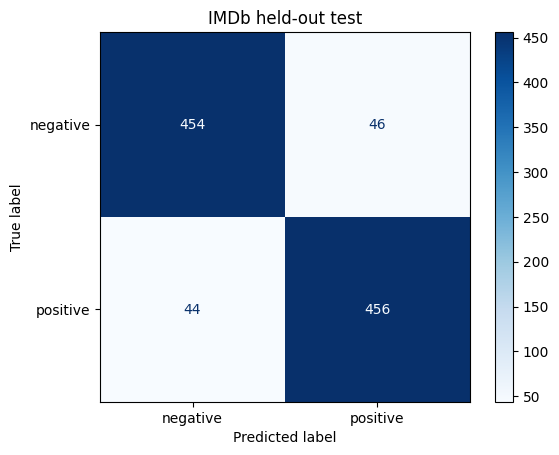

,text,prediction,p_negative,p_positive,confidence
0,I really enjoyed this movie.,positive,0.007671,0.992329,0.992329
1,The acting was good but the story was boring.,negative,0.997352,0.002648,0.997352
2,I did not like the ending.,negative,0.833107,0.166893,0.833107


Ví dụ tự nhập không có gold label; không dùng cột label giả để đánh giá.


In [13]:
final_model, final_length=restore('finetuned')
test_metrics,test_predictions=pc.predict_frame(final_model,test_df,tokenizer,final_length,BATCH_SIZE,DEVICE)
test_predictions.to_csv(OUT/'test_predictions.csv',index=False)
display(pd.DataFrame([test_metrics]))
cm=confusion_matrix(test_predictions.y_true,test_predictions.y_pred,labels=[0,1])
ConfusionMatrixDisplay(cm,display_labels=pc.LABEL_NAMES).plot(cmap='Blues',values_format='d'); plt.title('IMDb held-out test'); plt.show()
example_texts=['I really enjoyed this movie.', 'The acting was good but the story was boring.', 'I did not like the ending.']
example_frame=pd.DataFrame({'text':example_texts,'label':[0]*len(example_texts)})
_,app=pc.predict_frame(final_model,example_frame,tokenizer,final_length,BATCH_SIZE,DEVICE)
app['prediction']=app.y_pred.map({0:'negative',1:'positive'})
display(app[['text','prediction','p_negative','p_positive','confidence']])
print('Ví dụ tự nhập không có gold label; không dùng cột label giả để đánh giá.')

## 20. Error Analysis — chọn mẫu để phân tích riêng
**Thực nghiệm:** Xuất tất cả lỗi và hai nhóm FP/FN; chọn tối thiểu 3 FP (true negative → predicted positive), 3 FN (true positive → predicted negative), và 2 lỗi có confidence cao nhất. Hai mẫu tự tin có thể trùng FP/FN và được gắn nhãn nhóm riêng; số mẫu khác nhau tối thiểu là 6 nếu đủ mỗi nhóm. Nếu không đủ, notebook báo rõ. Phân tích và giả thuyết được viết sau trong `error_analytic.md`; không tự suy đoán nguyên nhân.

In [14]:
wrong=test_predictions[test_predictions.y_true != test_predictions.y_pred].copy()
wrong['error_type']=np.where(wrong.y_pred.eq(1),'false positive','false negative')
wrong=wrong.sort_values('confidence',ascending=False)
wrong.to_csv(OUT/'all_errors.csv',index=False)
fp=wrong[wrong.error_type.eq('false positive')].head(3).assign(selection='3 false positives')
fn=wrong[wrong.error_type.eq('false negative')].head(3).assign(selection='3 false negatives')
high=wrong.head(2).assign(selection='2 highest-confidence errors')
selected=pd.concat([fp,fn,high],ignore_index=True)
selected['hypothesis']='Để phân tích sau'
selected.to_csv(OUT/'selected_errors.csv',index=False)
print(f'FP: {len(wrong[wrong.error_type.eq("false positive")])}, FN: {len(wrong[wrong.error_type.eq("false negative")])}, tổng lỗi: {len(wrong)}')
if len(fp)<3 or len(fn)<3 or len(high)<2: print('CHƯA ĐỦ mẫu lỗi theo yêu cầu trên tập test này.')
with pd.option_context('display.max_colwidth',None):
    display(selected[['selection','source_id','text','y_true','y_pred','confidence','error_type','hypothesis']])

FP: 46, FN: 44, tổng lỗi: 90


,selection,source_id,text,y_true,y_pred,confidence,error_type,hypothesis
0,3 false positives,train/neg/10087_4.txt,"This is probably the first entry in the ""Lance O'Leary/Nurse Keat"" detective series; in subsequent O'Leary films, he was played by much younger actors than Guy Kibbee.<br /><br />A group of relatives (all played by well-known character actors) gathers in an old house (on a rainy nite, of course!) to speak to a wealthy relative, who goes into a coma.<br /><br />While they wait for him to recover, all sorts of mysterious goings-on happen, including a couple of murders.<br /><br />A creepy film; worth seeing!",0,1,0.994678,false positive,Để phân tích sau
1,3 false positives,test/neg/12405_4.txt,"Your ability to enjoy The Ashes of Time may depend on our expectations before stepping into the theater. Even its most strident supporters seem to agree that audiences can be split right up the middle in their appreciation of this unique film.<br /><br />Unlike most HK actioners, the battle scenes are curiously kept at a distance. When they do happen, they're rendered in a jerky style in which it's difficult to make out exactly what's occurring on screen. The dramatic scenes can be extravagantly beautiful, with the of Maggie Cheung, Brigitte Lin, and a roll-call of HK's top acting talent chewing up the scenery. As with some of Wong Kar-wai's early work, the dialog could be more precise. <br /><br />In short, The Ashes of Time requires a forgiving attitude. Released around the same time as Wong Kar-wai's spectacularly successful Chungking Express, it's clear that the director isn't as confident working with the elements of the martial arts film. Anyone looking for tense action is likely to be disappointed. But those intrigued by the director's aesthetic will likely find this a unique experience at the very least.",0,1,0.993579,false positive,Để phân tích sau
2,3 false positives,train/neg/6473_3.txt,"As a child the first installment (""The Little Mermaid"") was my favorite movie. It was filled with great characters, songs, and a fun family film. A week or so again I watched this movie for the first time. I believe that this movie was like most sequels and didn't surpass their original. I think that I feel this way possibly because I had high expectations and I have grown up. However, it is not a bad film.<br /><br />It starts when Ariel has just given birth to a beautiful child, Melody. Eric and Ariel feel threatened by Morgana (Eurselas' sister), so they build a large wall around their house which lies on the sea. As Melody grows up she begins to wonder outside of the walls where she is forbidden to go. Trouble stirs up as Morgana tries to take control of the seven seas.<br /><br />I don't want to give away any of the movie so you have to see it to find out. I did like that the voices are the same and again wonderful singing. I think this is a good family film though overall!",0,1,0.993417,false positive,Để phân tích sau
3,3 false negatives,test/pos/688_7.txt,"This seemed to be a lackluster film to me that betrays a low budget with poor cinematography and not all that great of a job of editing. It may be of interest to those who know something about submarines during the World War II era, but I recommend that all others beware. Many of the scenes in this film were flat and some of the actors were a bit weak. The story about the men getting called back to duty during a short leave seems realistic enough, but there's no real pacing or tension in the story. I also had a tough time understanding what the actors were saying, partially due to some strong English accents and perhaps some due to an inferior job of sound recording. I give this a 55/100. Most folks will want to ""steer"" clear.",1,0,0.997709,false negative,Để phân tích sau
4,3 false negatives,train/pos/5240_7.txt,"Some of the acting was a bit suspect. I remember that asswipe Alexander Walker (Evening Standard critic, yeah OK, he's now dead) launched into a rant about

### Phân tích sau khi chạy
Tạo `error_analytic.md` từ `selected_errors.csv` với bảng **Text | True | Pred | Confidence | Error type | Hypothesis**. Xem toàn văn, phần bị cắt và ngữ cảnh trước khi đề xuất nguyên nhân; chỉ gọi sarcasm, negation, tokenization... khi có bằng chứng. Ghi rõ mẫu trùng nhóm và các giới hạn nếu thiếu mẫu.

## 21. Confidence Analysis
**Thực nghiệm:** confidence = max(softmax(logits)); chia thấp < 0.60, trung bình [0.60, 0.90), cao ≥ 0.90. Ngưỡng mang tính quy ước, không phải hiệu chỉnh xác suất.

In [15]:
confidence_df=test_predictions.copy()
confidence_df['band']=pd.cut(confidence_df.confidence,[-np.inf,.6,.9,np.inf],labels=['low','medium','high'],right=False)
confidence_df['correct']=confidence_df.y_true.eq(confidence_df.y_pred)
confidence_summary=confidence_df.groupby('band',observed=False).agg(n=('correct','size'),accuracy=('correct','mean'),mean_confidence=('confidence','mean')).reset_index()
confidence_summary.to_csv(OUT/'confidence_summary.csv',index=False); display(confidence_summary)
display(confidence_df[(confidence_df.band=='high') & ~confidence_df.correct][['text','y_true','y_pred','confidence']].head(5))

,band,n,accuracy,mean_confidence
0,low,29,0.586207,0.556718
1,medium,124,0.701613,0.768931
2,high,847,0.951594,0.985606


,text,y_true,y_pred,confidence
51,Your ability to enjoy The Ashes of Time may de...,0,1,0.993579
118,I desperately want to give this movie a 10...I...,0,1,0.942830
186,"As a child the first installment (""The Little ...",0,1,0.993417
190,"But sadly due to rights issues, that almost ce...",1,0,0.940151
230,1969 was the year. New York City was the place...,1,0,0.971052


### Trả lời — Confidence Analysis

**Không.** Nhóm confidence cao (≥ 0,90) có **847 mẫu**, accuracy **95,16%**, tức vẫn có **41 mẫu sai**. Các nhóm thấp/trung bình đạt **58,62% / 70,16%**. Confidence phản ánh độ chắc chắn của dự đoán, **không bảo đảm dự đoán đúng**.

## 22. Ablation / Analysis
**Thực nghiệm có kiểm soát:** sử dụng lại Experiment 2 (frozen vs fine-tuned); cùng pretrained encoder, data, split, length, epoch, optimizer và seed; thay đổi việc cập nhật encoder. So sánh số tham số trainable, chất lượng và thời gian. Experiments 1, 3, 4 cung cấp các phép so sánh bổ sung.

In [16]:
display(exp2[['run_id','frozen','parameters_trainable','accuracy','f1_macro','training_time_s']])
exp2.to_csv(OUT/'exp22_ablation.csv',index=False)
print('Outputs:', OUT.resolve())

,run_id,frozen,parameters_trainable,accuracy,f1_macro,training_time_s
0,frozen,True,1538,0.738,0.737621,177.085604
1,finetuned,False,109483778,0.916,0.915997,444.115516


Outputs: /content/lab8_artifacts


### Trả lời — Ablation / Analysis

1. **Ảnh hưởng của freezing:** Frozen giảm accuracy từ **91,6% xuống 73,8%** (−**17,8 điểm %**), Macro F1 từ **91,60% xuống 73,76%**; đổi lại nhanh hơn (**177,1 s** so với **444,1 s**) và chỉ train **1.538** thay vì **109.483.778** tham số.
2. **Giới hạn:** Chỉ **1 seed**, **một validation split**, **8.000 mẫu quick** và **3 epochs**; chưa đánh giá độ dao động hay tối ưu siêu tham số riêng, nên chưa khái quát cho mọi dữ liệu/cấu hình.

In [17]:

# Xuất đầy đủ 4 deliverables của LAB 08
OUT.mkdir(parents=True, exist_ok=True)

# 1. results.csv — tổng hợp tất cả training runs
results = pd.concat([
    pd.DataFrame(records.values()),
    pd.DataFrame(data_records),
    pd.DataFrame(length_records)
], ignore_index=True)

results = results.drop_duplicates(
    subset="run_id", keep="last"
)
results.to_csv(OUT / "results.csv", index=False)

# 2. data_efficiency.png
ax = exp3.plot(
    x="fraction",
    y=["accuracy", "f1_macro"],
    marker="o",
    ylim=(0, 1),
    figsize=(8, 5),
    title="Data Efficiency"
)
ax.set_xlabel("Training data fraction")
ax.set_ylabel("Validation score")
ax.figure.savefig(
    OUT / "data_efficiency.png",
    dpi=200, bbox_inches="tight"
)
plt.close(ax.figure)

# 3. confusion_matrix.png
cm = confusion_matrix(
    test_predictions.y_true,
    test_predictions.y_pred,
    labels=[0, 1]
)
disp = ConfusionMatrixDisplay(
    cm, display_labels=pc.LABEL_NAMES
)
disp.plot(cmap="Blues", values_format="d")
plt.title("IMDb Test Confusion Matrix")
plt.savefig(
    OUT / "confusion_matrix.png",
    dpi=200, bbox_inches="tight"
)
plt.close()

# 4. confidence_analysis.png
ax = confidence_summary.set_index("band")[
    ["accuracy", "mean_confidence"]
].plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1),
    rot=0,
    title="Accuracy vs Mean Confidence"
)
ax.set_ylabel("Score")
ax.figure.savefig(
    OUT / "confidence_analysis.png",
    dpi=200, bbox_inches="tight"
)
plt.close(ax.figure)

# Kiểm tra
required = [
    "results.csv",
    "data_efficiency.png",
    "confusion_matrix.png",
    "confidence_analysis.png"
]
for name in required:
    path = OUT / name
    print(f"{'OK' if path.exists() else 'MISSING'}: {path}")


OK: lab8_artifacts/results.csv
OK: lab8_artifacts/data_efficiency.png
OK: lab8_artifacts/confusion_matrix.png
OK: lab8_artifacts/confidence_analysis.png


In [18]:

from google.colab import drive
import shutil

drive.mount('/content/drive')
shutil.copytree('/content/lab8_artifacts', '/content/drive/MyDrive/lab8_artifacts', dirs_exist_ok=True)
print("Đã copy toàn bộ kết quả lên Google Drive!")


Mounted at /content/drive
Đã copy toàn bộ kết quả lên Google Drive!


## 26. Individual Learning Check — Trả lời ngắn

1. **Pretraining vs fine-tuning:** Pretraining học biểu diễn chung từ dữ liệu lớn; fine-tuning điều chỉnh trọng số pretrained cho tác vụ cụ thể.
2. **MLM:** Dự đoán token bị che bằng ngữ cảnh hai phía.
3. **Tokenizer:** Biến văn bản thành token IDs cho model xử lý.
4. **Subword:** Tách từ hiếm/mới thành đơn vị nhỏ hơn, giảm vấn đề ngoài từ vựng.
5. **[CLS]:** Biểu diễn vị trí đầu chuỗi, thường được dùng cho classification.
6. **Attention mask:** Đánh dấu token hợp lệ và vị trí padding.
7. **Frozen encoder:** Không cập nhật trọng số encoder khi train.
8. **Fine-tuning:** Có thể cập nhật encoder và classification head (full fine-tuning).
9. **Tập nhỏ:** Pretrained có đặc trưng học sẵn nên cần ít dữ liệu downstream hơn.
10. **Domain shift:** Không; hiệu năng có thể giảm khi phân phối dữ liệu thay đổi.
11. **Sequence length:** Attention toàn cục tạo ma trận tương tác kích thước T×T, chi phí O(T²).
12. **Confidence:** Không bảo đảm đúng; thí nghiệm có **41** dự đoán sai dù confidence ≥ 0,90.

## 27. Error Analysis — Câu hỏi bắt buộc

1. **Model nào hưởng lợi khi ít dữ liệu?** Pretrained BERT: dùng **800 mẫu** đã đạt **88,8%** validation accuracy; chưa có scratch ở 10% để so sánh trực tiếp cùng mức.
2. **Pretrained tốt hơn scratch chứng minh gì?** Trọng số pretrained giúp học tác vụ hiệu quả hơn **trong cấu hình này**, không chứng minh luôn vượt trội ở mọi bài toán.
3. **Nếu frozen gần fine-tuned?** Biểu diễn pretrained đã phù hợp tác vụ, lợi ích cập nhật encoder có thể nhỏ. **Thực nghiệm này không như vậy** (73,8% so với 91,6%).
4. **Nếu fine-tuning tốt hơn nhiều?** Điều chỉnh encoder theo domain/tác vụ là quan trọng; ở đây accuracy hơn **17,8 điểm %**.
5. **Nếu đổi domain giảm mạnh?** Có thể do khác cách dùng từ, phong cách, độ dài, phân phối hoặc quy tắc nhãn. Với Amazon, chỉ giảm **0,7 điểm %**, chưa phải giảm mạnh.
6. **Nếu length tăng nhưng metric gần như không đổi, thời gian tăng mạnh?** Không nên tăng tiếp nếu lợi ích không bù chi phí; lựa chọn theo đánh đổi chất lượng/tài nguyên.